# Two bears in one crop: does it cause the Tonja / Hertha mix-ups?

Tonja (`002`) and Hertha (`003`) live together in Tierpark Berlin, and the model mixes them up one way: **Tonja → Hertha 5 times, Hertha → Tonja once** (validation). Berlin has the lowest accuracy (79.4%; Tonja alone 68.8%), and the two bears are barely separated in the embedding space.

**How the data is labeled:** each video (tracklet) has one label, the bear the crop follows. When a second bear walks into the crop, it is **not labeled**; it is just part of the picture (e.g. `003C02T066`, labeled Hertha, shows two bears side by side the whole time). The baseline averages all frames, so such a video's embedding is partly the *other* bear.

**Experiment** (nothing is trained; validation videos vs the training gallery; the test split is never used):
1. Count the bears in every frame of Tonja's and Hertha's videos with Mask R-CNN (animals with score ≥ 0.5; a bear found twice under two labels counts once).
2. Rebuild their videos' embeddings from the **single-bear frames** only.
3. **Control:** drop the same number of **random** frames instead (fewer frames alone can change the result).

**How to read it:**
- Mix-ups drop with single-bear frames but not with random drops: the second bear was causing them.
- Nothing changes: the mix-ups come from the two bears looking alike or sharing an enclosure (see `background_test.ipynb`).

This uses the same 5 frames per video as the background test, so the reference is the **5-frame** baseline (a bit below the 20-frame 88.84%).

**Known limits:** two bears that overlap closely can be found as one (undercount), and a sliver of a bear at the edge counts as a second bear (the `second_box_frac` check below handles that).

## 0. Imports and setup

In [1]:
import os
import sys
from pathlib import Path

# Run from the repo folder (one level up from notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt

import heatmaps
import background_test as bt
import two_bears

## 1. The frames: 5 per video (same as the background test), and Tonja's and Hertha's among them

In [2]:
frames, embeddings = heatmaps.load_frames()
keep = bt.pick_frames(frames)
pair = keep[keep["identity"].isin(two_bears.BEARS)]
pair.groupby(["identity", "split"]).size()

identity  split     
002       train         380
          validation     80
003       train         410
          validation     90
dtype: int64

## 2. Count the bears in every frame

About 25 minutes on a CPU. Saved to `data/animal_counts.csv` and reused next time.

In [3]:
segmenter, animal_ids = bt.load_segmenter()
counts = two_bears.count_animals(pair, segmenter, animal_ids)
counts["animals"].value_counts()

animals
1    888
2     61
0      7
3      4
Name: count, dtype: int64

## 3. How common is a second bear?

In [4]:
two_bears.how_common(pair, counts)

frames  two_bear_frames_%  videos  videos_with_two_bears
identity split                                                               
002      train          380                8.2      76                     19
         validation      80                2.5      16                      2
003      train          410                7.6      82                     16
         validation      90                1.1      18                      1

## 4. Check by eye

Frames where 2+ animals were found. If many of these show only one bear, the counts are not trustworthy.

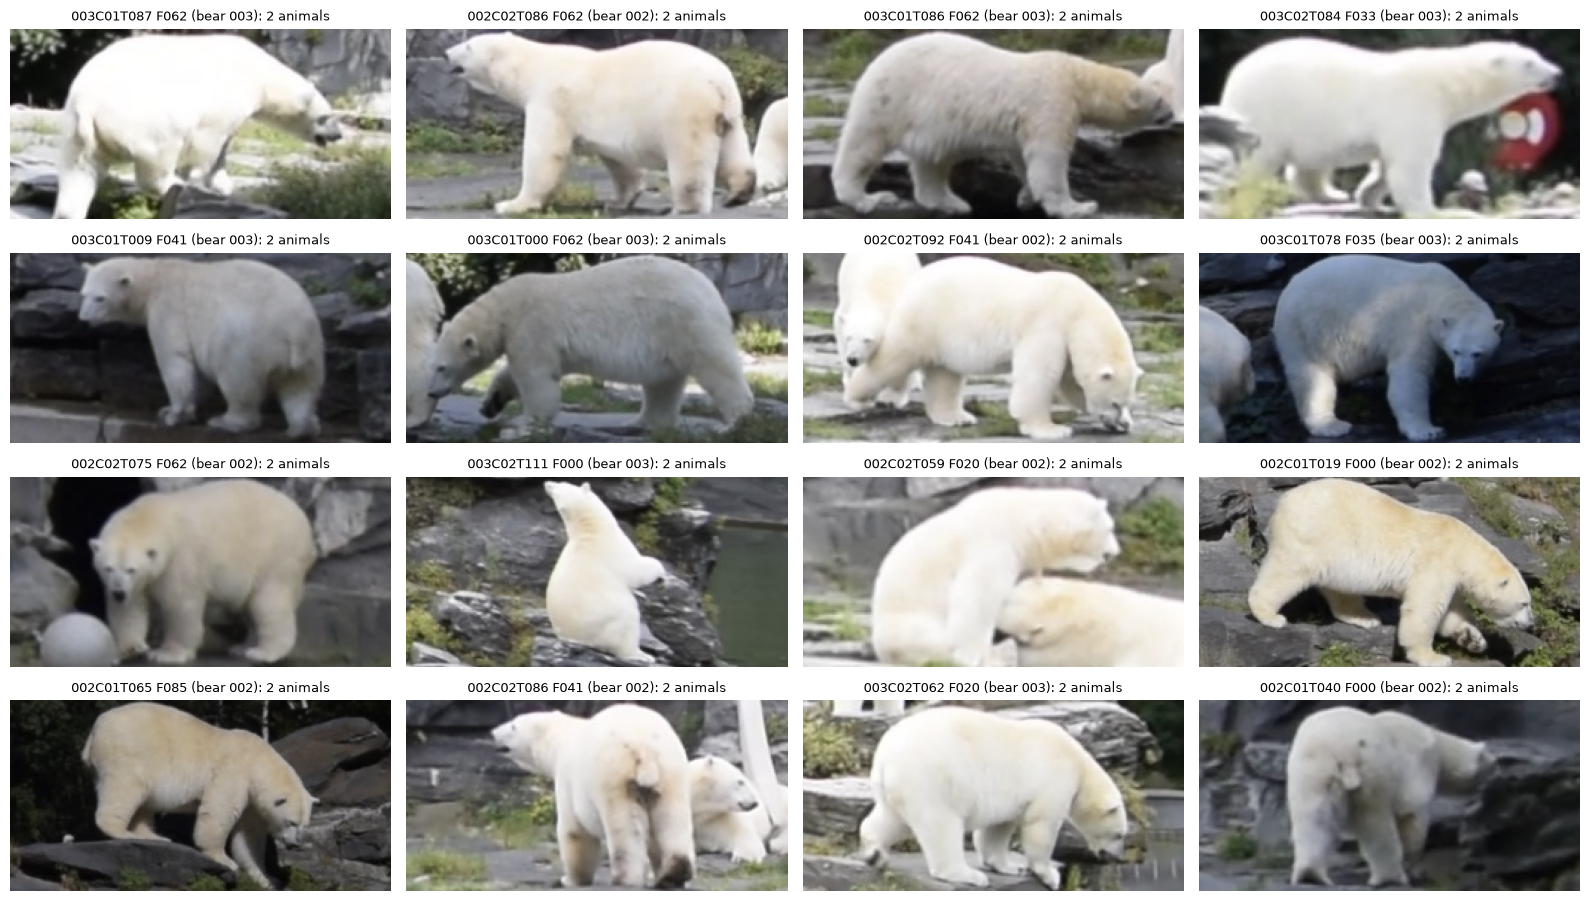

In [5]:
fig, path = two_bears.plot_two_bear_frames(pair, counts)
plt.show()

## 5. The experiment

- `gap_within_minus_between`: how separated Tonja and Hertha are (training videos; bigger = easier to tell apart).
- `frames_dropped`: frames removed from Tonja's and Hertha's videos.
- `videos_kept_whole`: videos where every frame shows two bears, so they keep all their frames.

In [6]:
table, results = two_bears.two_bear_experiment(keep, embeddings, counts)
table.round(3)

,version,accuracy_%,002_accuracy_%,003_accuracy_%,002->003_mistakes,003->002_mistakes,gap_within_minus_between,frames_dropped,videos_kept_whole
0,all frames,84.651,56.250,88.889,6.00,0.0,0.014,NaN,NaN
1,single-bear frames,84.651,56.250,88.889,6.00,0.0,0.014,55.0,2.0
2,random drop (mean of 20),84.535,54.688,88.889,5.95,0.0,0.014,55.0,NaN


Same, but only counting a **substantial** second bear (its box covers at least 10% of the frame), so slivers at the edge are ignored:

In [7]:
table_big, results_big = two_bears.two_bear_experiment(keep, embeddings, counts, min_second_frac=0.1)
table_big.round(3)

,version,accuracy_%,002_accuracy_%,003_accuracy_%,002->003_mistakes,003->002_mistakes,gap_within_minus_between,frames_dropped,videos_kept_whole
0,all frames,84.651,56.25,88.889,6.0,0.0,0.014,NaN,NaN
1,single-bear frames,84.186,50.00,88.889,6.0,0.0,0.015,41.0,2.0
2,random drop (mean of 20),84.140,50.00,88.889,6.2,0.0,0.013,41.0,NaN


## 6. Which of Tonja's and Hertha's validation videos changed?

In [8]:
before = results["all frames"].set_index("sequence")
after = results["single-bear frames"].set_index("sequence")
both = before[["identity", "predicted", "correct", "margin"]].merge(
    after[["predicted", "correct", "margin"]], left_index=True, right_index=True, suffixes=("", "_single"))
both[both["identity"].isin(two_bears.BEARS) & (both["correct"] != both["correct_single"])].round(3)

,identity,predicted,correct,margin,predicted_single,correct_single,margin_single
sequence,,,,,,,


## 7. What we found

- **A second bear is rare.** It was flagged in 8.2% (Tonja) and 7.6% (Hertha) of training frames, and 1-2.5% of validation frames. By eye (section 4), about half of the flagged frames really show a second bear; the others are the same bear found twice, or a toy. So the true rate is even lower.
- **Removing those frames changes nothing.** Accuracy (84.7%), Tonja's accuracy (56.3%), the 6 Tonja -> Hertha mistakes and the gap between the two bears (0.014) are the same with all frames, with single-bear frames and with random drops, and no validation video changes its prediction. Counting only a substantial second bear gives the same picture.
- **So the unlabeled second bear is not why Tonja is mistaken for Hertha.** What remains: the two bears look alike in MegaDescriptor's features (Tonja is still only 62.5% with the bear alone in the background test) and they share an enclosure.
- **Limit:** two bears that overlap closely can be counted as one, so a few two-bear frames may have been missed.